In [ ]:
import pandas as pd

# Read Excel file
df = pd.read_excel("Synthetic_Data_Preprocessing.xlsx")

# Display first 5 records
print(df.head())

# Display information
print(df.info())

# Display last 5 records
print(df.tail())

# Display descriptive statistics
print(df.describe())

# Check missing values
print(df.isnull().sum())

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Marks"] = df["Marks"].fillna(df["Marks"].median())
df["Salary"] = df["Salary"].fillna(df["Salary"].median())

# Check missing values again
print(df.isnull().sum())

# Find duplicate records
print(df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Calculate Q1 and Q3
Q1 = df["Marks"].quantile(0.25)
Q3 = df["Marks"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate bounds
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df["Marks"] < lower) |
    (df["Marks"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)

print("Outliers:")
print(outliers)

FileNotFoundError: [Errno 2] No such file or directory: 'Synthetic_Data_Preprocessing.xlsx'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported succcesfully")
data={
    'student':["s1","s2","s3",'s4','s5','s6','s7','s8','s9','s10','s11'],
    'age':[20,30,35,40,45,55,25,30,20,21,31],
    'Attensence':[75,67,37,44,33,44,53,90,100,89,76],
    'Marks':[78,90,60,60,70,80,65,95,75,78,97],
    'Study_Hour':[3,4,5,6,7,8,9,11,12,7,9],
    'Department':['EEC','EEC','EEE','EEC','CSE','CSE','EEC','EEE','CSE','EEC','EEC']
}
df=pd.DataFrame(data)
print(df)


Libraries imported succcesfully
   student  age  Attensence  Marks  Study_Hour Department
0       s1   20          75     78           3        EEC
1       s2   30          67     90           4        EEC
2       s3   35          37     60           5        EEE
3       s4   40          44     60           6        EEC
4       s5   45          33     70           7        CSE
5       s6   55          44     80           8        CSE
6       s7   25          53     65           9        EEC
7       s8   30          90     95          11        EEE
8       s9   20         100     75          12        CSE
9      s10   21          89     78           7        EEC
10     s11   31          76     97           9        EEC


In [ ]:
print("First five Records:")
print(df.head())
print("\nDataset Shape:")
print(df.shape)
print("\nDataTypes:")
print(df.dtypes)
print("\nStatistical Summary")
print(df.describe())
print("\nLast five Record")
print(df.tail())

First five Records:
  student  age  Attensence  Marks  Study_Hour Department
0      s1   20          75     78           3        EEC
1      s2   30          67     90           4        EEC
2      s3   35          37     60           5        EEE
3      s4   40          44     60           6        EEC
4      s5   45          33     70           7        CSE

Dataset Shape:
(11, 6)

DataTypes:
student       object
age            int64
Attensence     int64
Marks          int64
Study_Hour     int64
Department    object
dtype: object

Statistical Summary
             age  Attensence      Marks  Study_Hour
count  11.000000   11.000000  11.000000   11.000000
mean   32.000000   64.363636  77.090909    7.363636
std    11.126545   23.410565  12.957272    2.802596
min    20.000000   33.000000  60.000000    3.000000
25%    23.000000   44.000000  67.500000    5.500000
50%    30.000000   67.000000  78.000000    7.000000
75%    37.500000   82.500000  85.000000    9.000000
max    55.000000  100.000

Text(0, 0.5, 'Average Marks')

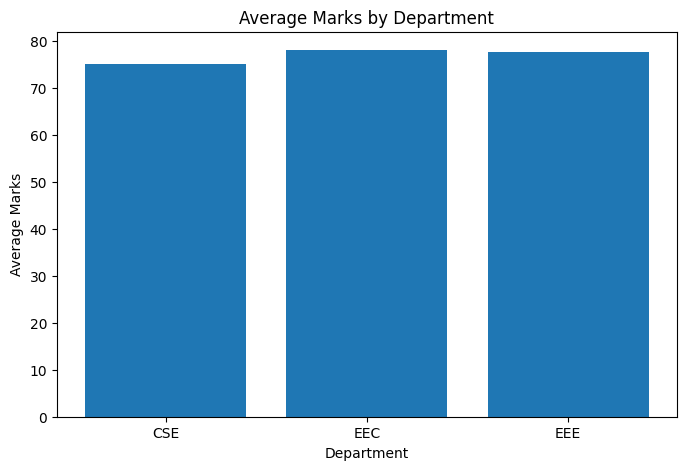

In [ ]:
#Barchart
department_marks=df.groupby('Department')['Marks'].mean()
plt.figure(figsize=(8,5))#8=width,5=size it is in inches form
plt.bar(department_marks.index,department_marks.values)
plt.title('Average Marks by Department')
plt.xlabel('Department')
plt.ylabel('Average Marks')



Text(0, 0.5, 'Average Marks')

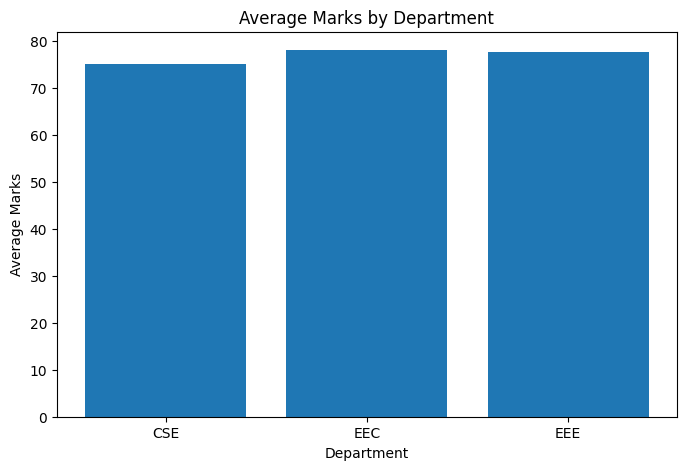

In [ ]:
department_marks=df.groupby('Department')['Marks'].median()
plt.figure(figsize=(8,5))#8=width,5=size it is in inches form
plt.bar(department_marks.index,department_marks.values)
plt.title('Average Marks by Department')
plt.xlabel('Department')
plt.ylabel('Average Marks')

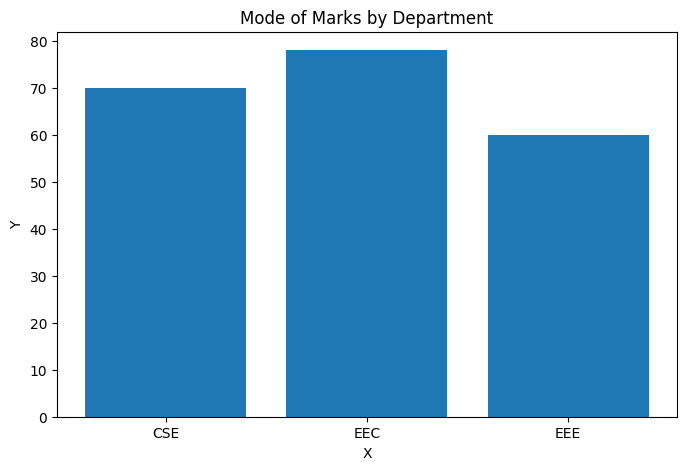

In [ ]:
department_marks = df.groupby('Department')['Marks'].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else None
)

plt.figure(figsize=(8,5))
plt.bar(department_marks.index, department_marks.values)

plt.title('Mode of Marks by Department')
plt.xlabel('X')
plt.ylabel('Y')

plt.show()

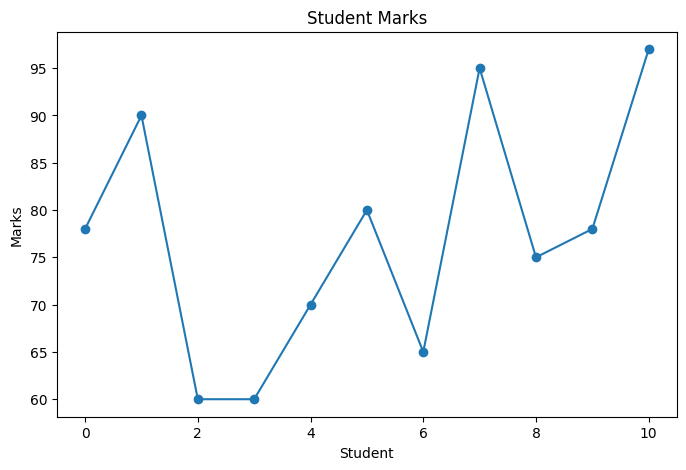

In [ ]:
#LineChart
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(df.index, df['Marks'],marker='o')

plt.title('Student Marks')
plt.xlabel('Student')
plt.ylabel('Marks')

plt.show()


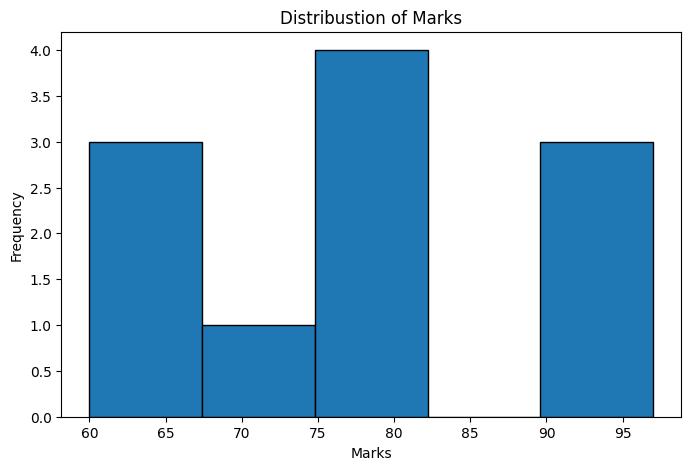

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['Marks'],bins=5,edgecolor='black')
plt.title('Distribustion of Marks')
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.show()


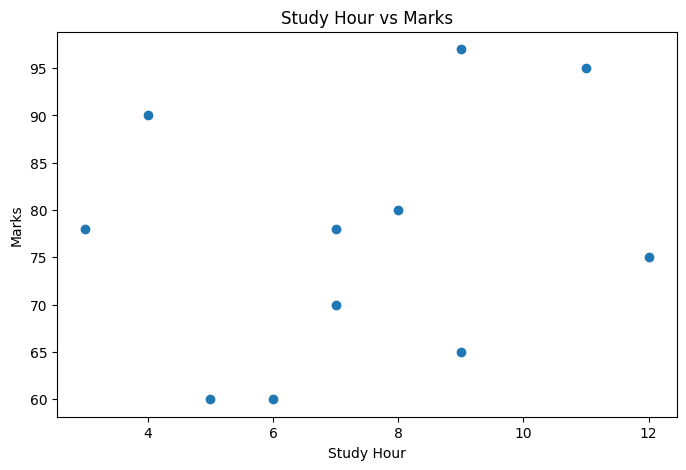

In [ ]:
#ScatterPlot
plt.figure(figsize=(8,5))
plt.scatter(df['Study_Hour'],df['Marks'])
plt.title('Study Hour vs Marks')
plt.xlabel("Study Hour")
plt.ylabel("Marks")
plt.show()

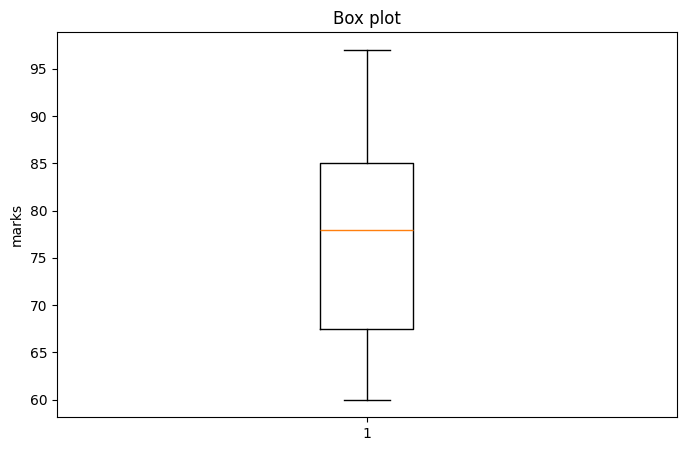

In [ ]:
#boxplot
plt.figure(figsize=(8,5))
plt.boxplot(df['Marks'],vert=True)
plt.title("Box plot")
plt.ylabel("marks")
plt.show()

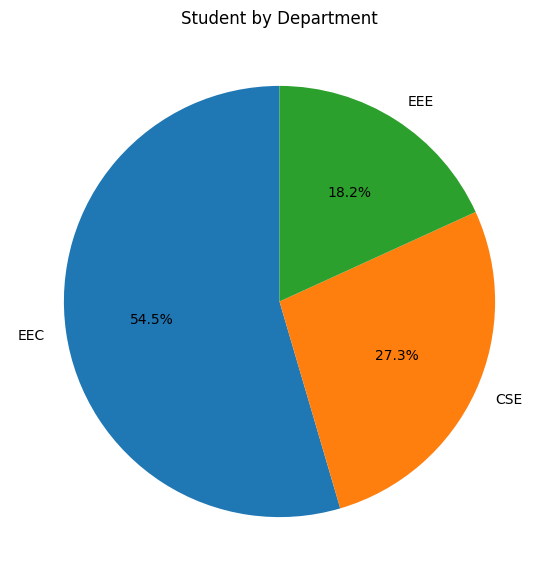

In [13]:
#piechart
department_count=df['Department'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(department_count.values,labels=department_count.index,autopct='%1.1f%%',startangle=90)
plt.title("Student by Department")
plt.grid()
plt.show()


                 age  Attensence     Marks  Study_Hour
age         1.000000   -0.743247 -0.142887   -0.067344
Attensence -0.743247    1.000000  0.592950    0.435214
Marks      -0.142887    0.592950  1.000000    0.244083
Study_Hour -0.067344    0.435214  0.244083    1.000000


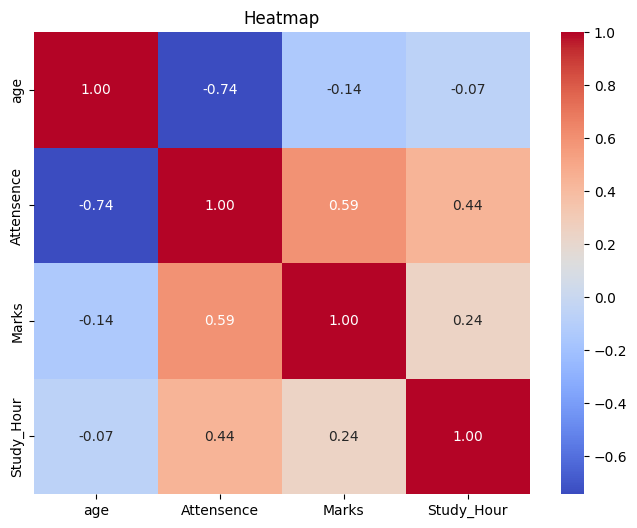

In [11]:
# Heatmap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'student': ["s1", "s2", "s3", "s4", "s5", "s6", "s7", "s8", "s9", "s10", "s11"],
    'age': [20, 30, 35, 40, 45, 55, 25, 30, 20, 21, 31],
    'Attensence': [75, 67, 37, 44, 33, 44, 53, 90, 100, 89, 76],
    'Marks': [78, 90, 60, 60, 70, 80, 65, 95, 75, 78, 97],
    'Study_Hour': [3, 4, 5, 6, 7, 8, 9, 11, 12, 7, 9],
    'Department': ['EEC', 'EEC', 'EEE', 'EEC', 'CSE', 'CSE', 'EEC', 'EEE', 'CSE', 'EEC', 'EEC']
}

# Convert dictionary into DataFrame
df = pd.DataFrame(data)

# Select numerical columns
numeric_data = df.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

print(correlation_matrix)

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Heatmap")
plt.show()
